# Volatility Comparison: Machine A vs. Machine B

Phase 4 found a counterintuitive result. Machine B (high volatility, tuned for rare large wins) had a higher hit frequency than Machine A (low volatility, tuned for frequent small wins), at 49.9% vs. 36.7%. The cause was a common filler symbol that produces frequent small consolation wins below the bet. This notebook visualizes that finding.

In [1]:
import sys
from pathlib import Path


def find_repo_root(start: Path) -> Path:
    current = start.resolve()
    while not (current / "engine").is_dir():
        if current.parent == current:
            raise RuntimeError("could not locate repo root (no engine/ found)")
        current = current.parent
    return current


REPO_ROOT = find_repo_root(Path.cwd())
sys.path.insert(0, str(REPO_ROOT))

%matplotlib inline
import random

import matplotlib.pyplot as plt
import numpy as np

from analytics.statistics import compute_statistics
from engine.config import load_game_config
from simulation.simulate import run_spins

In [2]:
NUM_SPINS = 500_000

machine_a = load_game_config(str(REPO_ROOT / "configs" / "volatility_low.json"))
machine_b = load_game_config(str(REPO_ROOT / "configs" / "volatility_high.json"))

batch_a = run_spins(machine_a, NUM_SPINS, bet=1.0, rng=random.Random(1))
batch_b = run_spins(machine_b, NUM_SPINS, bet=1.0, rng=random.Random(2))

stats_a = compute_statistics(batch_a)
stats_b = compute_statistics(batch_b)

print(
    f"Machine A (low vol):  RTP={stats_a.rtp:.2%}  hit_freq={stats_a.hit_frequency:.2%}  "
    f"std_dev={stats_a.std_dev:.2f}  skew={stats_a.skewness:.1f}  max_win={stats_a.max_win_multiplier:.1f}x"
)
print(
    f"Machine B (high vol): RTP={stats_b.rtp:.2%}  hit_freq={stats_b.hit_frequency:.2%}  "
    f"std_dev={stats_b.std_dev:.2f}  skew={stats_b.skewness:.1f}  max_win={stats_b.max_win_multiplier:.1f}x"
)

Machine A (low vol):  RTP=95.86%  hit_freq=36.67%  std_dev=1.81  skew=3.7  max_win=56.5x
Machine B (high vol): RTP=96.19%  hit_freq=49.95%  std_dev=3.67  skew=71.3  max_win=706.0x


## Overlaid win-size histogram (log-log scale, wins only)

On a linear scale the histogram is dominated by the no-win bar. Excluding zero and using log-log axes reveals the difference in shape: Machine A's wins cluster in a narrow band, while Machine B's extend into a long, thin tail.

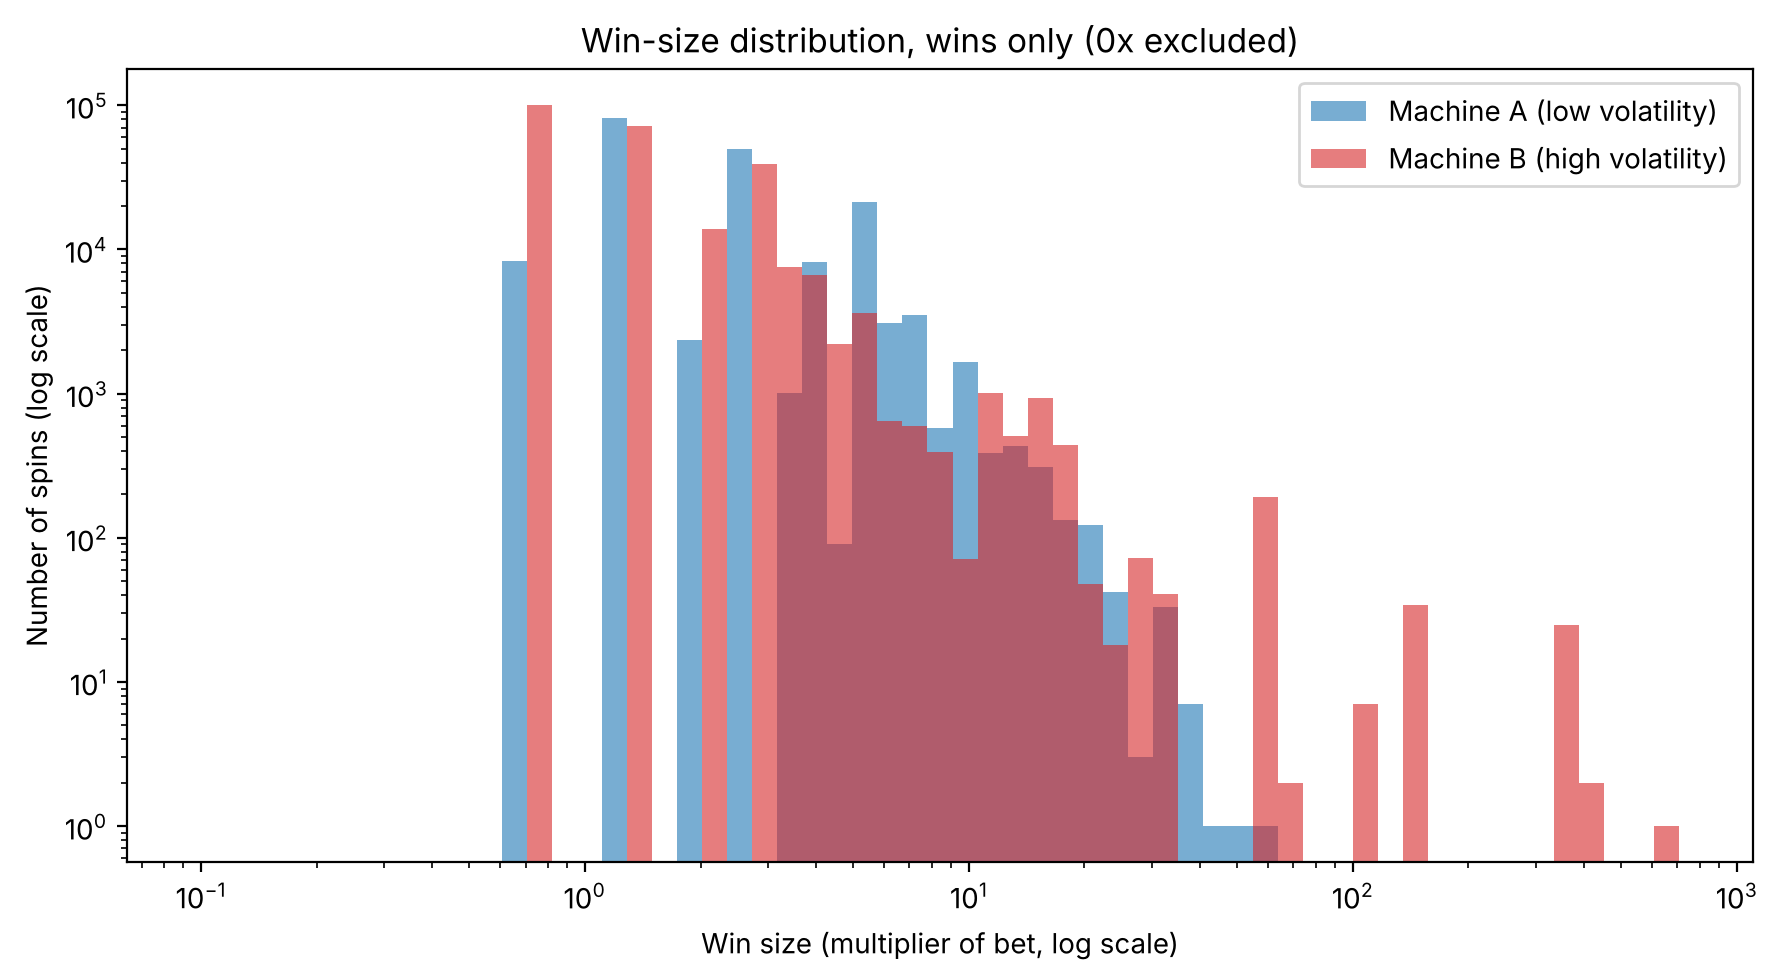

In [3]:
multipliers_a = np.array(batch_a.payouts) / batch_a.bet
multipliers_b = np.array(batch_b.payouts) / batch_b.bet

max_win = max(multipliers_a.max(), multipliers_b.max())
bins = np.logspace(-1, np.log10(max_win + 1), 60)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(multipliers_a[multipliers_a > 0], bins=bins, alpha=0.6, label="Machine A (low volatility)", color="#1f77b4")
ax.hist(multipliers_b[multipliers_b > 0], bins=bins, alpha=0.6, label="Machine B (high volatility)", color="#d62728")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Win size (multiplier of bet, log scale)")
ax.set_ylabel("Number of spins (log scale)")
ax.set_title("Win-size distribution, wins only (0x excluded)")
ax.legend()
plt.tight_layout()
plt.show()

## Why Machine B's hit frequency is higher: sub-bet consolation wins

Splitting spins into no win, a win below the bet, and a win above the bet makes the Phase 4 finding concrete. Almost all of Machine B's extra hit frequency comes from sub-bet wins.

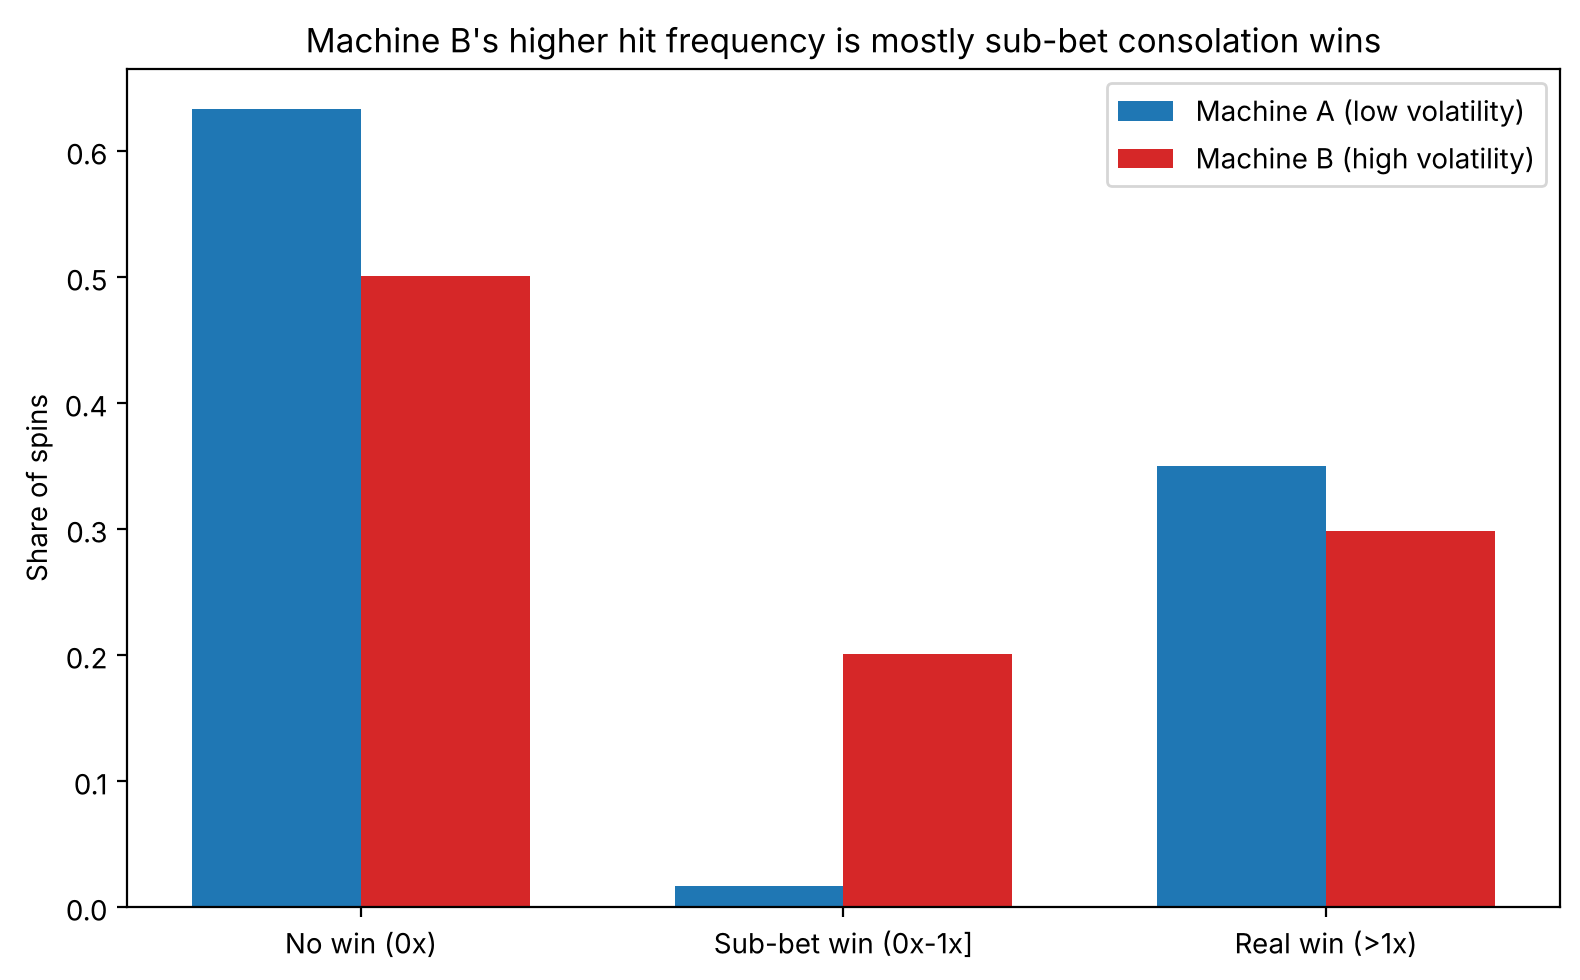

In [4]:
def win_size_breakdown(multipliers):
    no_win = np.mean(multipliers == 0)
    sub_bet = np.mean((multipliers > 0) & (multipliers <= 1))
    real_win = np.mean(multipliers > 1)
    return [no_win, sub_bet, real_win]


breakdown_a = win_size_breakdown(multipliers_a)
breakdown_b = win_size_breakdown(multipliers_b)

labels = ["No win (0x)", "Sub-bet win (0x-1x]", "Real win (>1x)"]
x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width / 2, breakdown_a, width, label="Machine A (low volatility)", color="#1f77b4")
ax.bar(x + width / 2, breakdown_b, width, label="Machine B (high volatility)", color="#d62728")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Share of spins")
ax.set_title("Machine B's higher hit frequency is mostly sub-bet consolation wins")
ax.legend()
plt.tight_layout()
plt.show()

## Takeaway

Both charts show the same result. Machine B hits more often, but many of those hits return less than the bet, which matches the common complaint that high-volatility slots hit often but rarely feel like a real win. Hit frequency alone would hide this, and the win-size distribution reveals it.